# 09 — Memory test: can the reservoir supply the history?

**Why this notebook exists.** In notebooks 07–08 the fly reservoir, all three controls and plain ridge tied. The diagnosis (progress log): the 28 input features already contain lags and rolling means of the target, so the reservoir's fading memory duplicates what the features carry, and the readout learned to switch the states off (RMSE rose steadily with `state_weight`; the best configurations penalised the states almost completely). That experiment cannot show whether the fly's wiring helps or not.

**This notebook gives the reservoir a job only it can do.** The inputs are *history-free*: current-month values only (state-based, non-state and one-sided deaths this month, neighbour conflict this month, number of neighbours, the seven V-Dem indices). All lags, rolling means, maxima, trends, months-since-conflict, streaks and the never-conflict flag are removed. Whatever the model knows about the past must now come from the reservoir's own dynamics.

### Comparisons (all on the same folds, rows and tuning budget)
| Reference | What it is | Role |
|---|---|---|
| **A: ridge, current values only** | no memory at all | the floor the reservoir must beat |
| **B: ridge, full 28 features** | hand-built lags and rolling means (notebook 05) | the ceiling: what explicit history gives |
| **fly / weight-shuffled / rewired / random** | reservoir on current values, readout `[states, current values]` | how much of the gap between A and B each network recovers |

**Memory recovered** = (RMSE A − RMSE network) / (RMSE A − RMSE B). 0 = no memory extracted, 1 = as good as the hand-built history, above 1 = better than it.

### How to read the outcomes
- **All reservoirs ≈ A:** the dynamics are not producing useful memory; the fly adds nothing.
- **All reservoirs recover a lot and tie each other:** the reservoir mechanism works but the fly's wiring is not special (any random network of that size and density does it).
- **Fly recovers more than the controls, by more than the seed spread and with a paired interval excluding 0:** evidence that specific wiring helps. Fly vs shuffled isolates synapse strengths, fly vs rewired isolates specific connections beyond the degree pattern, fly vs random isolates structure of any kind.

### Search space changes (documented because they differ from 07)
`input_scale` 0.05–5 (stronger drive, more nonlinearity), `leak` 0.05–1, `state_weight` 0.05–5 (states may be weighted up to 5× the raw inputs). `rho` stays 0.3–1.4. Same 40 draws for every network. **The locked test set is never scored.** `QUICK_TEST = True` runs 2 configurations at horizon 1.

### Follow-up sections (added 2026-10-02 after the first full run)
Sections 7–10 test *why* the controls tie the fly. **7:** how large a fly advantage the data can still hide (equivalence bounds). **8:** whether the reservoirs' better onset ranking is real (cluster bootstrap on average precision). **9:** where the memory comes from — a linear reservoir (the `input_scale` → 0 limit, since the tanh search preferred the bottom of its range) and two banks of leaky units with **no recurrence at all**. **10:** whether the 96 MBONs beat 96 random units (size-matched readout). **9c:** a baseline with no reservoir at all (ridge on moving averages of the inputs) and equivalence bounds for the linear and no-recurrence comparisons. Each experiment writes its own log, so the first full run of sections 1–6 is reused and only the new work is computed. Full run of 7–10: roughly 2–3 hours on a laptop.

## Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

root = Path.cwd().resolve()
while not (root / ".git").exists():
    if root == root.parent:
        raise FileNotFoundError("Open this notebook from inside the DACSS_ML_FP repo.")
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score

from src.paths import ROOT
from src.features.build import FEATURES
from src.eval.splits import FOLDS
from src.eval.paired import cluster_bootstrap_rmse_diff, cluster_bootstrap_ap_diff
from src.models.common import HORIZONS as ALL_H, KINDS
from src.models.readout import LAMBDAS, ridge_path
from src.models.reservoir_search import (ReservoirLab, sample_configs, tune, best_configs,
                                         SPACE_MEMORY, SPACE_LINEAR, SPACE_BANK, BANKS)
from src.networks.controls import KINDS as NETS

# ------------------------------------------------------------------ settings
QUICK_TEST = False
N_ITER = 40
SEED = 42
N_READOUT = 1024
N_SEEDS = 5
N_BOOT = 2000
N_MECH = 20          # configurations per network in the mechanism section (9)
MECH_SEEDS = 3       # extra seeds for the mechanism section's best configurations
HORIZONS = [1] if QUICK_TEST else ALL_H
if QUICK_TEST:
    N_ITER, N_SEEDS, N_BOOT = 2, 1, 300
    N_MECH, MECH_SEEDS = 2, 1
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)
sfx = "_quicktest" if QUICK_TEST else ""
LOG = RESULTS / f"memory_log{sfx}.csv"
BASE = RESULTS / f"baseline_predictions{sfx}.parquet"
pd.set_option("display.width", 160, "display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8a85", "axes.labelcolor": "#3d3d3a", "xtick.color": "#5f5e5a",
    "ytick.color": "#5f5e5a", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 1.8, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})

NET_NAMES = {"fly": "fly", "shuffled": "weight-shuffled", "rewired": "degree-preserving rewired", "er": "random (Erdős–Rényi)"}
COLORS = {"A: ridge, current values": "#8a8a85", "B: ridge, full features": "#2a78d6", "fly": "#1baf7a",
          "weight-shuffled": "#eb6834", "degree-preserving rewired": "#9b59b6", "random (Erdős–Rényi)": "#c9a227"}
print(f"QUICK_TEST={QUICK_TEST}  horizons={HORIZONS}  N_ITER={N_ITER}  seeds={N_SEEDS}")

QUICK_TEST=False  horizons=[1, 3, 6, 12]  N_ITER=40  seeds=5


## 1. The history-free input set
The assertion below is the leakage-and-design guard: no input may carry information from before the origin month.

In [2]:
MEMORY_FEATURES = ["log_sb", "log_ns", "log_os", "log_nbr", "n_land_nbrs",
                   "v2x_polyarchy", "v2x_libdem", "v2x_civlib", "v2x_clphy", "v2x_rule", "v2x_corr", "v2x_regime"]
REMOVED = [f for f in FEATURES if f not in MEMORY_FEATURES]
HISTORY_TOKENS = ("lag", "mean", "max", "trend", "since", "streak", "never")
assert not any(any(t in f for t in HISTORY_TOKENS) for f in MEMORY_FEATURES), "a history feature slipped in"
assert all(any(t in f for t in HISTORY_TOKENS) for f in REMOVED if f not in ("log_ns", "log_os") and not f.startswith("v2x")
           and f not in ("log_sb", "log_nbr", "n_land_nbrs")), "unexpected removal"
print(f"{len(MEMORY_FEATURES)} current-value inputs kept: {MEMORY_FEATURES}")
print(f"{len(REMOVED)} removed: {REMOVED}")

12 current-value inputs kept: ['log_sb', 'log_ns', 'log_os', 'log_nbr', 'n_land_nbrs', 'v2x_polyarchy', 'v2x_libdem', 'v2x_civlib', 'v2x_clphy', 'v2x_rule', 'v2x_corr', 'v2x_regime']
16 removed: ['log_sb_lag1', 'log_sb_lag2', 'log_sb_lag3', 'log_sb_lag6', 'log_sb_lag12', 'log_sb_mean3', 'log_sb_mean6', 'log_sb_mean12', 'log_sb_max12', 'sb_trend', 'log_ns_mean3', 'log_os_mean3', 'log_months_since_conflict', 'conflict_streak', 'never_conflict_seen', 'log_nbr_mean3']


In [3]:
lab = ReservoirLab(horizons=HORIZONS, n_random=N_READOUT, seed=SEED, features=MEMORY_FEATURES)
print("Inputs (months x countries x features):", lab.inp.U.shape)
for h in HORIZONS:
    print(f"horizon {h:>2}: {len(lab.y[h]):,} forecast rows")

Inputs (months x countries x features): (444, 178, 12)
horizon  1: 71,904 forecast rows
horizon  3: 71,554 forecast rows
horizon  6: 71,030 forecast rows
horizon 12: 69,988 forecast rows


## 2. Reference A: ridge with current values only
This is the model with no memory. It is computed with the same readout code and the same folds as everything else; reference B is the ridge row of `results/leaderboard.csv`.

In [4]:
KEEP = ["gwno", "country", "month", "y", "kind", "at_risk", "event"]
lb = pd.read_csv(RESULTS / ("leaderboard_quicktest.csv" if QUICK_TEST else "leaderboard.csv"))
refA, A_pred = {}, []
for h in HORIZONS:
    ti, si = lab.loc[h]; Z = lab.inp.R[ti, si]; trm, vam = lab.masks[h]; y = lab.y[h]
    P = ridge_path(Z, y, trm, vam)
    r = np.mean([np.sqrt(np.mean((y[va][:, None] - p) ** 2, axis=0)) for va, p in zip(vam, P)], axis=0)
    j = int(r.argmin()); refA[h] = r[j]
    d = lab.tables[h]
    for f, va, p in zip(FOLDS, vam, P):
        A_pred.append(d.loc[va, KEEP].assign(horizon=h, model="A: ridge, current values", fold=f.name, pred=p[:, j]))
A_pred = pd.concat(A_pred, ignore_index=True)
refB = lb[lb["model"] == "ridge"].set_index("horizon")["rmse"].to_dict()
ref = pd.DataFrame({"A: ridge, current values": refA, "B: ridge, full features": {h: refB[h] for h in HORIZONS}})
ref["gap A - B"] = ref.iloc[:, 0] - ref.iloc[:, 1]
display(ref.round(4))
print("The gap A - B is the amount of forecasting skill that explicit history provides. A reservoir has something to recover only if this gap is clearly positive.")

,"A: ridge, current values","B: ridge, full features",gap A - B
1,0.5672,0.5033,0.0639
3,0.6491,0.5707,0.0784
6,0.7066,0.6216,0.0850
12,0.7569,0.6887,0.0682


The gap A - B is the amount of forecasting skill that explicit history provides. A reservoir has something to recover only if this gap is clearly positive.


## 3. Tune the four networks (same 40 configurations each)

In [5]:
CONFIGS = sample_configs(N_ITER, SEED, SPACE_MEMORY)
print("Search space: rho 0.3-1.4, input_scale 0.05-5 (log), leak 0.05-1, state_weight 0.05-5 (log)")
for kind in NETS:
    tune(lab, kind, CONFIGS, LOG)
log = pd.read_csv(LOG)
print("networks in log:", sorted(log["network"].unique()))

Search space: rho 0.3-1.4, input_scale 0.05-5 (log), leak 0.05-1, state_weight 0.05-5 (log)
networks in log: ['er', 'fly', 'rewired', 'shuffled']


## 4. Leaderboard and memory recovered

In [6]:
best = best_configs(log)
tab = pd.DataFrame({"A: ridge, current values": pd.Series(refA), "B: ridge, full features": pd.Series(refB)}).loc[HORIZONS]
for kind in NETS:
    tab[NET_NAMES[kind]] = best[(best["network"] == kind) & (best["variant"] == "random")].set_index("horizon")["rmse"]
display(tab.round(4))
rec = tab[[NET_NAMES[k] for k in NETS]].rsub(tab["A: ridge, current values"], axis=0).div(tab["A: ridge, current values"] - tab["B: ridge, full features"], axis=0)
print("Memory recovered = (A - network) / (A - B):  0 = none, 1 = as good as hand-built history")
display(rec.round(3))
print("MBON-only readout (96 units) vs 1,024 random units, fly:")
mb = best[best["network"] == "fly"].pivot(index="horizon", columns="variant", values="rmse")[["random", "mbon"]]
display(mb.rename(columns={"random": "1,024 random units", "mbon": "96 MBONs"}).round(4))
bp = best[(best["variant"] == "random")].copy()
pp = bp["params"].apply(json.loads).apply(pd.Series)
bp = pd.concat([bp[["network", "horizon", "rmse"]], pp, bp[["lambda_id"]].rename(columns={"lambda_id": "ridge lambda id"})], axis=1)
print("Best configurations (check for values at the edge of their range):")
display(bp.sort_values(["horizon", "network"]).round(3))

,"A: ridge, current values","B: ridge, full features",fly,weight-shuffled,degree-preserving rewired,random (Erdős–Rényi)
1,0.5672,0.5033,0.5051,0.5055,0.5064,0.5046
3,0.6491,0.5707,0.5754,0.5747,0.5749,0.5738
6,0.7066,0.6216,0.6267,0.6257,0.6261,0.6248
12,0.7569,0.6887,0.6960,0.6956,0.6957,0.6936


Memory recovered = (A - network) / (A - B):  0 = none, 1 = as good as hand-built history


,fly,weight-shuffled,degree-preserving rewired,random (Erdős–Rényi)
1,0.972,0.966,0.951,0.980
3,0.940,0.949,0.947,0.961
6,0.940,0.952,0.947,0.962
12,0.893,0.899,0.897,0.929


MBON-only readout (96 units) vs 1,024 random units, fly:


variant,"1,024 random units",96 MBONs
horizon,,
1,0.5051,0.5125
3,0.5754,0.5797
6,0.6267,0.6307
12,0.6960,0.7003


Best configurations (check for values at the edge of their range):


,network,horizon,rmse,input_scale,leak,rho,state_weight,ridge lambda id
4,er,1,0.505,0.051,0.825,1.078,1.435,1
12,fly,1,0.505,0.058,0.655,0.646,0.520,1
20,rewired,1,0.506,0.058,0.655,0.646,0.520,0
28,shuffled,1,0.505,0.058,0.655,0.646,0.520,0
5,er,3,0.574,0.052,0.535,0.759,0.139,3
13,fly,3,0.575,0.075,0.236,0.350,0.224,3
21,rewired,3,0.575,0.063,0.315,1.299,0.151,3
29,shuffled,3,0.575,0.063,0.315,1.299,0.151,3
6,er,6,0.625,0.052,0.535,0.759,0.139,3
14,fly,6,0.627,0.075,0.236,0.350,0.224,3


In [7]:
g = (log[(log["variant"] == "random")].groupby(["network", "horizon", "config_id", "lambda_id"])["rmse"].mean()
     .groupby(["network", "horizon", "config_id"]).min().reset_index().merge(pd.DataFrame(CONFIGS).assign(config_id=lambda d: d.index), on="config_id"))
rows = []
for (net, h), s in g.groupby(["network", "horizon"]):
    c = s[["rmse", "rho", "input_scale", "leak", "state_weight"]].corr(method="spearman")["rmse"]
    rows.append({"network": NET_NAMES[net], "horizon": h, **{f"rank corr with {k}": c[k] for k in ["rho", "input_scale", "leak", "state_weight"]}})
sens = pd.DataFrame(rows); print("How RMSE depends on each hyperparameter (Spearman correlation across the 40 configurations):")
display(sens[sens["network"] == "fly"].set_index("horizon").drop(columns="network").round(2))

How RMSE depends on each hyperparameter (Spearman correlation across the 40 configurations):


,rank corr with rho,rank corr with input_scale,rank corr with leak,rank corr with state_weight
horizon,,,,
1,-0.10,0.93,-0.15,0.01
3,-0.17,0.87,0.27,0.19
6,-0.14,0.89,0.20,0.12
12,-0.05,0.90,0.12,0.23


## 5. Seeds and paired bootstrap
The best configuration of each network is re-run with new random input matrices (and, for controls, new random graphs). The paired comparison uses the seed-0 predictions of each network's best configuration, with the same country-cluster bootstrap as notebooks 06 and 08. **RMSE(A) − RMSE(B); negative = A better.**

In [8]:
SEEDS = RESULTS / f"memory_seeds{sfx}.csv"
if SEEDS.exists():
    seeds = pd.read_csv(SEEDS)
else:
    rows = []
    for kind in NETS:
        for h in HORIZONS:
            b = best[(best["network"] == kind) & (best["variant"] == "random") & (best["horizon"] == h)].iloc[0]
            cfg = json.loads(b["params"]); lam = int(b["lambda_id"])
            for s in range(0, N_SEEDS + 1):
                res = lab.evaluate(kind, cfg, w_seed=s, graph_seed=s, variants=("random",), horizons=[h])
                rows.append({"network": NET_NAMES[kind], "horizon": h, "seed": s, "rmse": res[("random", h)][0][:, lam].mean()})
            print(f"{NET_NAMES[kind]:<28} horizon {h:>2} done", flush=True)
    seeds = pd.DataFrame(rows); seeds.to_csv(SEEDS, index=False)
extra = seeds[seeds["seed"] > 0]
sm = extra.groupby(["horizon", "network"])["rmse"].agg(["mean", "std"]).unstack("network")
print("mean over new seeds:"); display(sm["mean"].round(4)); print("standard deviation over new seeds:"); display(sm["std"].round(4))

mean over new seeds:


network,degree-preserving rewired,fly,random (Erdős–Rényi),weight-shuffled
horizon,,,,
1,0.5068,0.5052,0.5044,0.5050
3,0.5746,0.5751,0.5740,0.5745
6,0.6259,0.6261,0.6251,0.6255
12,0.6949,0.6953,0.6939,0.6943


standard deviation over new seeds:


network,degree-preserving rewired,fly,random (Erdős–Rényi),weight-shuffled
horizon,,,,
1,0.0012,0.0002,0.0008,0.0006
3,0.0002,0.0002,0.0003,0.0003
6,0.0002,0.0003,0.0004,0.0004
12,0.0006,0.0007,0.0003,0.0002


In [9]:
RP = []
for kind in NETS:
    for h in HORIZONS:
        b = best[(best["network"] == kind) & (best["variant"] == "random") & (best["horizon"] == h)].iloc[0]
        cfg = json.loads(b["params"]); lam = int(b["lambda_id"])
        P = lab.evaluate(kind, cfg, w_seed=0, graph_seed=0, variants=("random",), horizons=[h], predictions=True)[("random", h)][2]
        d = lab.tables[h]
        for f, va, p in zip(FOLDS, lab.masks[h][1], P):
            RP.append(d.loc[va, KEEP].assign(horizon=h, model=NET_NAMES[kind], fold=f.name, pred=p[:, lam]))
RP = pd.concat(RP, ignore_index=True)
base = pd.read_parquet(BASE); B_pred = base[base["model"] == "ridge"].assign(model="B: ridge, full features")
ALLP = pd.concat([A_pred, B_pred, RP], ignore_index=True)
RP.to_parquet(RESULTS / f"memory_predictions{sfx}.parquet")

A_, B_ = "A: ridge, current values", "B: ridge, full features"
pairs = [("fly", A_), ("fly", B_), (B_, A_), ("fly", "weight-shuffled"), ("fly", "degree-preserving rewired"), ("fly", "random (Erdős–Rényi)")]
rows = []
for h in HORIZONS:
    wide = ALLP[ALLP["horizon"] == h].pivot_table(index=["gwno", "month"], columns="model", values="pred")
    yy = ALLP[(ALLP["horizon"] == h) & (ALLP["model"] == A_)].set_index(["gwno", "month"])["y"]
    wide = wide.join(yy).reset_index().dropna()
    for a, b_ in pairs:
        r = cluster_bootstrap_rmse_diff(wide["y"], wide[a], wide[b_], wide["gwno"], B=N_BOOT, seed=SEED)
        rows.append({"horizon": h, "A": a, "B": b_, **r})
paired = pd.DataFrame(rows); paired["significant"] = (paired["lo"] > 0) | (paired["hi"] < 0)
display(paired.round(4))
paired.round(5).to_csv(RESULTS / f"paired_memory{sfx}.csv", index=False)

,horizon,A,B,diff,lo,hi,p_a_better,significant
0,1,fly,"A: ridge, current values",-0.0625,-0.0771,-0.0484,1.0000,True
1,1,fly,"B: ridge, full features",0.0019,-0.0013,0.0057,0.1395,False
2,1,"B: ridge, full features","A: ridge, current values",-0.0644,-0.0806,-0.0490,1.0000,True
3,1,fly,weight-shuffled,-0.0003,-0.0026,0.0027,0.6250,False
4,1,fly,degree-preserving rewired,-0.0014,-0.0041,0.0013,0.8370,False
5,1,fly,random (Erdős–Rényi),0.0005,-0.0010,0.0021,0.2450,False
6,3,fly,"A: ridge, current values",-0.0742,-0.0978,-0.0502,1.0000,True
7,3,fly,"B: ridge, full features",0.0048,-0.0012,0.0128,0.0760,False
8,3,"B: ridge, full features","A: ridge, current values",-0.0790,-0.1038,-0.0560,1.0000,True
9,3,fly,weight-shuffled,0.0007,-0.0008,0.0030,0.2395,False


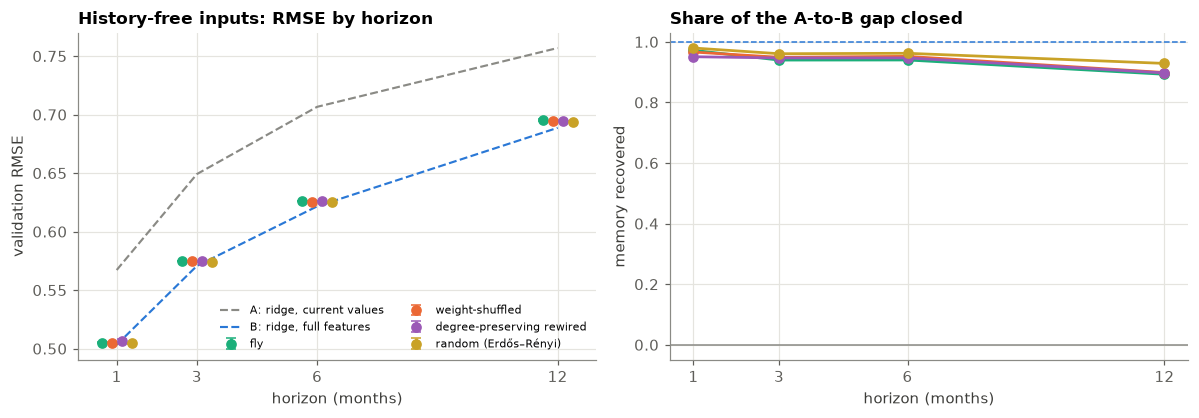

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
names = [NET_NAMES[k] for k in NETS]
ax = axes[0]
for i, n in enumerate(names):
    s = extra[extra["network"] == n].groupby("horizon")["rmse"].agg(["mean", "std"]).reindex(HORIZONS)
    ax.errorbar(np.array(HORIZONS) + (i - 1.5) * 0.25, s["mean"], yerr=s["std"].fillna(0), fmt="o", capsize=3, color=COLORS[n], label=n)
for m in [A_, B_]:
    ax.plot(HORIZONS, tab[m], color=COLORS[m], ls="--", lw=1.4, label=m)
ax.set_xticks(HORIZONS); ax.set_xlabel("horizon (months)"); ax.set_ylabel("validation RMSE"); ax.set_title("History-free inputs: RMSE by horizon")
ax.legend(frameon=False, fontsize=7, ncol=2)
ax = axes[1]
for i, n in enumerate(names):  
    ax.plot(HORIZONS, rec[n], marker="o", color=COLORS[n], label=n)
ax.axhline(0, color="#8a8a85", lw=1); ax.axhline(1, color="#2a78d6", lw=1, ls="--")
ax.set_xticks(HORIZONS); ax.set_xlabel("horizon (months)"); ax.set_ylabel("memory recovered"); ax.set_title("Share of the A-to-B gap closed")
plt.tight_layout(); plt.show()

## 6. Where is the gain? Row type and onset detection

In [11]:
show = [A_, B_] + names
rows = []
for (h, m), p in ALLP[ALLP["model"].isin(show)].groupby(["horizon", "model"]):
    r = {"horizon": h, "model": m, "all rows": np.sqrt(np.mean((p["y"] - p["pred"]) ** 2))}
    for k in KINDS:
        s = p[p["kind"] == k]; r[k] = np.sqrt(np.mean((s["y"] - s["pred"]) ** 2))
    a = p[p["at_risk"]]; r["onset AP"] = average_precision_score(a["event"], a["pred"])
    rows.append(r)
bykind = pd.DataFrame(rows)
for h in HORIZONS:
    print(f"Horizon {h}: RMSE by row type and onset average precision (pooled folds 1-5)")
    display(bykind[bykind["horizon"] == h].drop(columns="horizon").set_index("model").reindex(show).round(3))
bykind.round(4).to_csv(RESULTS / f"memory_by_kind{sfx}.csv", index=False)

Horizon 1: RMSE by row type and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
"A: ridge, current values",0.568,0.099,2.092,1.064,1.842,0.095
"B: ridge, full features",0.504,0.114,1.815,0.953,1.584,0.106
fly,0.506,0.118,1.806,0.959,1.592,0.110
weight-shuffled,0.506,0.117,1.807,0.960,1.592,0.110
degree-preserving rewired,0.507,0.118,1.809,0.960,1.601,0.118
random (Erdős–Rényi),0.505,0.120,1.803,0.960,1.575,0.102


Horizon 3: RMSE by row type and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
"A: ridge, current values",0.650,0.133,2.241,1.240,1.920,0.105
"B: ridge, full features",0.571,0.142,1.958,1.084,1.649,0.103
fly,0.576,0.144,1.958,1.101,1.654,0.118
weight-shuffled,0.575,0.142,1.961,1.098,1.655,0.116
degree-preserving rewired,0.575,0.143,1.959,1.100,1.656,0.116
random (Erdős–Rényi),0.574,0.143,1.955,1.097,1.654,0.118


Horizon 6: RMSE by row type and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
"A: ridge, current values",0.707,0.157,2.332,1.381,1.952,0.113
"B: ridge, full features",0.622,0.161,2.062,1.199,1.693,0.115
fly,0.627,0.165,2.055,1.220,1.695,0.133
weight-shuffled,0.626,0.163,2.058,1.216,1.696,0.133
degree-preserving rewired,0.627,0.162,2.058,1.217,1.698,0.131
random (Erdős–Rényi),0.625,0.163,2.053,1.215,1.693,0.135


Horizon 12: RMSE by row type and onset average precision (pooled folds 1-5)


,all rows,stay quiet,onset,continuation,cessation,onset AP
model,,,,,,
"A: ridge, current values",0.758,0.179,2.419,1.480,1.923,0.156
"B: ridge, full features",0.690,0.177,2.239,1.318,1.753,0.149
fly,0.697,0.179,2.239,1.344,1.768,0.180
weight-shuffled,0.697,0.177,2.245,1.343,1.764,0.180
degree-preserving rewired,0.697,0.178,2.244,1.342,1.766,0.183
random (Erdős–Rényi),0.695,0.178,2.241,1.336,1.760,0.186


## 7. How tight is the null? Equivalence bounds
"Intervals span 0" invites the reply that the test had too little power. The intervals are narrow enough to say more: the **lower** end of each fly-vs-control interval is the largest fly advantage still consistent with the data. Dividing it by the A − B gap (pooled RMSE, the same rows) expresses it as a share of the skill that explicit history provides.

In [12]:
names = [NET_NAMES[k] for k in NETS]
gapAB = paired[(paired["A"] == B_) & (paired["B"] == A_)].set_index("horizon")["diff"].abs()
rows = []
for h in HORIZONS:
    for ctrl in names[1:]:
        r = paired[(paired["horizon"] == h) & (paired["A"] == "fly") & (paired["B"] == ctrl)].iloc[0]
        adv = max(0.0, -r["lo"])
        rows.append({"horizon": h, "control": ctrl, "fly - control": r["diff"], "lo": r["lo"], "hi": r["hi"],
                     "largest plausible fly advantage": adv, "as share of A-B gap": adv / gapAB[h]})
bounds = pd.DataFrame(rows)
display(bounds.round(4))
print(f"Largest fly advantage consistent with the data, any horizon or control: "
      f"{bounds['as share of A-B gap'].max():.1%} of the A-B gap (median {bounds['as share of A-B gap'].median():.1%}).")
bounds.round(5).to_csv(RESULTS / f"memory_bounds{sfx}.csv", index=False)

,horizon,control,fly - control,lo,hi,largest plausible fly advantage,as share of A-B gap
0,1,weight-shuffled,-0.0003,-0.0026,0.0027,0.0026,0.0401
1,1,degree-preserving rewired,-0.0014,-0.0041,0.0013,0.0041,0.0641
2,1,random (Erdős–Rényi),0.0005,-0.0010,0.0021,0.0010,0.0148
3,3,weight-shuffled,0.0007,-0.0008,0.0030,0.0008,0.0103
4,3,degree-preserving rewired,0.0005,-0.0004,0.0017,0.0004,0.0055
5,3,random (Erdős–Rényi),0.0017,0.0004,0.0034,0.0000,0.0000
6,6,weight-shuffled,0.0011,-0.0014,0.0046,0.0014,0.0166
7,6,degree-preserving rewired,0.0006,-0.0014,0.0031,0.0014,0.0160
8,6,random (Erdős–Rényi),0.0019,-0.0001,0.0048,0.0001,0.0014
9,12,weight-shuffled,0.0003,-0.0030,0.0039,0.0030,0.0440


Largest fly advantage consistent with the data, any horizon or control: 6.4% of the A-B gap (median 1.6%).


## 8. Onset detection: is the reservoirs' higher average precision real?
Section 6 showed every reservoir ranking onsets better than reference B at horizons 6 and 12 (and A beating B at 12). Average precision is computed on at-risk rows, using each model's regression prediction as the risk score. The same country-cluster bootstrap is used. **Here a POSITIVE difference means the first model is better** (higher AP), the opposite sign convention to RMSE. Per-fold AP shows whether one fold drives the result.

In [13]:
AP_PAIRS = [("fly", B_), ("random (Erdős–Rényi)", B_), (A_, B_), ("fly", A_)]
rows, frows = [], []
for h in HORIZONS:
    wide = ALLP[ALLP["horizon"] == h].pivot_table(index=["gwno", "month"], columns="model", values="pred")
    meta = (ALLP[(ALLP["horizon"] == h) & (ALLP["model"] == A_)]
            .set_index(["gwno", "month"])[["at_risk", "event", "fold"]])
    wide = wide.join(meta).reset_index().dropna()
    ar = wide[wide["at_risk"].astype(bool)]
    for a, b_ in AP_PAIRS:
        r = cluster_bootstrap_ap_diff(ar["event"].astype(bool), ar[a], ar[b_], ar["gwno"], B=N_BOOT, seed=SEED)
        rows.append({"horizon": h, "A": a, "B": b_, "events": int(ar["event"].sum()), **r})
    for fold, s in ar.groupby("fold"):
        if s["event"].sum() == 0:
            continue
        frows.append({"horizon": h, "fold": fold, "events": int(s["event"].sum()),
                      **{m: average_precision_score(s["event"].astype(bool), s[m]) for m in [A_, B_, "fly", "random (Erdős–Rényi)"]}})
ap_paired = pd.DataFrame(rows); ap_paired["significant"] = (ap_paired["lo"] > 0) | (ap_paired["hi"] < 0)
print("AP(A) - AP(B), country-cluster bootstrap. Positive = A ranks onsets better.")
display(ap_paired.round(4))
ap_paired.round(5).to_csv(RESULTS / f"memory_onset_ap{sfx}.csv", index=False)
print("Average precision by fold (at-risk rows):")
display(pd.DataFrame(frows).set_index(["horizon", "fold"]).round(3))

AP(A) - AP(B), country-cluster bootstrap. Positive = A ranks onsets better.


,horizon,A,B,events,diff,lo,hi,p_a_better,significant
0,1,fly,"B: ridge, full features",128,0.0041,-0.0067,0.0092,0.7345,False
1,1,random (Erdős–Rényi),"B: ridge, full features",128,-0.0033,-0.0206,0.0075,0.2075,False
2,1,"A: ridge, current values","B: ridge, full features",128,-0.0101,-0.0479,0.0119,0.1675,False
3,1,fly,"A: ridge, current values",128,0.0142,-0.0077,0.0468,0.8955,False
4,3,fly,"B: ridge, full features",177,0.0142,-0.0078,0.0253,0.8555,False
5,3,random (Erdős–Rényi),"B: ridge, full features",177,0.0150,-0.0053,0.0278,0.8965,False
6,3,"A: ridge, current values","B: ridge, full features",177,0.0013,-0.0573,0.0482,0.4070,False
7,3,fly,"A: ridge, current values",177,0.0129,-0.0334,0.0567,0.7505,False
8,6,fly,"B: ridge, full features",234,0.0175,-0.0101,0.0286,0.9040,False
9,6,random (Erdős–Rényi),"B: ridge, full features",234,0.0199,-0.0060,0.0322,0.9395,False


Average precision by fold (at-risk rows):


events  A: ridge, current values  B: ridge, full features    fly  random (Erdős–Rényi)
horizon fold                                                                                          
1       fold 1      25                     0.157                    0.163  0.149                 0.130
        fold 2      24                     0.248                    0.203  0.227                 0.226
        fold 3      23                     0.041                    0.063  0.064                 0.063
        fold 4      27                     0.044                    0.056  0.056                 0.054
        fold 5      29                     0.146                    0.171  0.170                 0.162
3       fold 1      34                     0.143                    0.126  0.133                 0.134
        fold 2      34                     0.241                    0.137  0.135                 0.135
        fold 3      32                     0.048                    0.081  0.082                 0.081
        fold 4      39                     0.042                    0.095  0.096                 0.093
        fold 5      38                     0.155                    0.206  0.208                 0.217
6       fold 1      45                     0.112                    0.127  0.126                 0.126
        fold 2      46                     0.135                    0.125  0.128                 0.125
        fold 3      43                     0.155                    0.092  0.115                 0.116
        fold 4      51                     0.062                    0.086  0.120                 0.121
        fold 5      49                     0.170                    0.253  0.259                 0.264
12      fold 1      63                     0.173                    0.185  0.209                 0.204
        fold 2      51                     0.094                    0.140  0.142                 0.139
        fold 3      67                     0.166                    0.123  0.165                 0.167
        fold 4      70                     0.117                    0.110  0.156                 0.166
        fold 5      69                     0.246                    0.327  0.325                 0.333

## 9. Mechanism: where does the reservoir's memory come from?
Two findings from sections 4–5 motivate this section: the best `input_scale` sat at the **bottom** of its range for every network (RMSE rose with input scale, Spearman about +0.9), and the controls tie the fly. Both suggest the reservoir is working as a *near-linear filter bank*. A linear reservoir's memory is set entirely by the eigenvalues of (1 − leak)·I + leak·Wᵀ, and rescaling every network to the same spectral radius makes those spectra similar, so a tie would be expected.

| Model | What it removes | If it matches the tanh networks... |
|---|---|---|
| **Linear reservoir** (fly and the three controls) | the nonlinearity (tanh → identity; the `input_scale` → 0 limit) | the nonlinear dynamics add nothing |
| **bank_single** | all recurrence: 1,024 independent leaky units, one shared leak rate | one time scale of fading memory is enough |
| **bank_multi** | all recurrence, but each unit has its own leak rate (log-uniform between the tuned slowest rate and 1) | the memory is the leak, not the network |

Same readout (1,024 units plus the 12 current inputs), ridge path, folds and rows as sections 3–5. The budget is `N_MECH` configurations per model, fewer than the 40 used for the tanh networks, which **favours the tanh networks** if anything. The linear search keeps rho below 0.95 so the system cannot diverge. Each experiment has its own log file, resumable like the others.

In [14]:
LIN_LOG = RESULTS / f"memory_linear_log{sfx}.csv"
BANK_LOG = RESULTS / f"memory_bank_log{sfx}.csv"
LIN_CONFIGS = sample_configs(N_MECH, SEED, SPACE_LINEAR, fixed={"activation": "linear"})
BANK_CONFIGS = sample_configs(N_MECH, SEED, SPACE_BANK)
for kind in NETS:
    tune(lab, kind, LIN_CONFIGS, LIN_LOG, variants=("random",))
for kind in BANKS:
    tune(lab, kind, BANK_CONFIGS, BANK_LOG, variants=("random",))
best_lin = best_configs(pd.read_csv(LIN_LOG)); best_bank = best_configs(pd.read_csv(BANK_LOG))

In [15]:
mech = tab[[A_, B_]].copy()
for kind in NETS:
    mech[f"{NET_NAMES[kind]} (tanh)"] = tab[NET_NAMES[kind]]
for kind in NETS:
    mech[f"{NET_NAMES[kind]} (linear)"] = best_lin[best_lin["network"] == kind].set_index("horizon")["rmse"]
for kind in BANKS:
    mech[kind] = best_bank[best_bank["network"] == kind].set_index("horizon")["rmse"]
print("Validation RMSE (mean over folds 1-5):")
display(mech.T.round(4))
rec_m = mech.drop(columns=[A_, B_]).rsub(mech[A_], axis=0).div(mech[A_] - mech[B_], axis=0)
print("Memory recovered = (A - model) / (A - B):")
display(rec_m.T.round(3))
print("Best configurations (look for values at the edge of their range):")
for name, b in [("linear", best_lin), ("banks", best_bank)]:
    pp = b["params"].apply(json.loads).apply(pd.Series)
    display(pd.concat([b[["network", "horizon", "rmse", "lambda_id"]], pp.drop(columns=["activation"], errors="ignore")], axis=1)
            .sort_values(["horizon", "network"]).round(3))

Validation RMSE (mean over folds 1-5):


,1,3,6,12
"A: ridge, current values",0.5672,0.6491,0.7066,0.7569
"B: ridge, full features",0.5033,0.5707,0.6216,0.6887
fly (tanh),0.5051,0.5754,0.6267,0.6960
weight-shuffled (tanh),0.5055,0.5747,0.6257,0.6956
degree-preserving rewired (tanh),0.5064,0.5749,0.6261,0.6957
random (Erdős–Rényi) (tanh),0.5046,0.5738,0.6248,0.6936
fly (linear),0.5027,0.5729,0.6237,0.6926
weight-shuffled (linear),0.5030,0.5732,0.6238,0.6928
degree-preserving rewired (linear),0.5030,0.5732,0.6238,0.6926
random (Erdős–Rényi) (linear),0.5027,0.5722,0.6225,0.6916


Memory recovered = (A - model) / (A - B):


,1,3,6,12
fly (tanh),0.972,0.940,0.940,0.893
weight-shuffled (tanh),0.966,0.949,0.952,0.899
degree-preserving rewired (tanh),0.951,0.947,0.947,0.897
random (Erdős–Rényi) (tanh),0.980,0.961,0.962,0.929
fly (linear),1.010,0.972,0.975,0.943
weight-shuffled (linear),1.005,0.968,0.974,0.940
degree-preserving rewired (linear),1.005,0.968,0.975,0.943
random (Erdős–Rényi) (linear),1.010,0.981,0.989,0.958
bank_single,0.921,0.929,0.919,0.888
bank_multi,1.015,0.963,0.971,0.953


Best configurations (look for values at the edge of their range):


,network,horizon,rmse,lambda_id,leak,rho,state_weight
0,er,1,0.503,0,0.786,0.911,3.081
4,fly,1,0.503,0,0.786,0.911,3.081
8,rewired,1,0.503,0,0.569,0.420,4.346
12,shuffled,1,0.503,0,0.569,0.420,4.346
1,er,3,0.572,1,0.618,0.899,0.075
5,fly,3,0.573,0,0.618,0.899,0.075
9,rewired,3,0.573,2,0.105,0.863,0.797
13,shuffled,3,0.573,3,0.105,0.863,0.797
2,er,6,0.623,1,0.618,0.899,0.075
6,fly,6,0.624,1,0.183,0.490,0.270


,network,horizon,rmse,lambda_id,input_scale,leak,state_weight
0,bank_multi,1,0.502,0,0.018,0.041,0.560
4,bank_single,1,0.508,0,0.174,0.153,0.062
1,bank_multi,3,0.574,4,0.013,0.038,0.270
5,bank_single,3,0.576,1,0.174,0.153,0.062
2,bank_multi,6,0.624,5,0.018,0.041,0.560
6,bank_single,6,0.628,1,0.174,0.153,0.062
3,bank_multi,12,0.692,5,0.019,0.012,0.224
7,bank_single,12,0.696,1,0.174,0.153,0.062


### 9b. Seeds and paired tests for the mechanism models
Best configurations re-run with `MECH_SEEDS` new input matrices (and, for the banks, new leak draws; for ER, new graphs). The paired tests answer three questions: does removing the nonlinearity hurt (fly tanh vs fly linear)? Does the fly's wiring help once the reservoir is linear (fly linear vs ER linear)? Does any network beat no recurrence at all (fly tanh vs bank_multi), and how much history does the bank recover on its own (bank_multi vs A and vs B)?

In [16]:
MSEEDS = RESULTS / f"memory_mech_seeds{sfx}.csv"
MECH_RUNS = [("fly", "linear", best_lin), ("er", "linear", best_lin), ("bank_single", "bank", best_bank), ("bank_multi", "bank", best_bank)]
def mech_label(kind, family):
    return f"{NET_NAMES[kind]} (linear)" if family == "linear" else kind
def best_row(b, kind, h):
    r = b[(b["network"] == kind) & (b["variant"] == "random") & (b["horizon"] == h)].iloc[0]
    return json.loads(r["params"]), int(r["lambda_id"])

if MSEEDS.exists():
    mseeds = pd.read_csv(MSEEDS)
else:
    rows = []
    for kind, fam, b in MECH_RUNS:
        for h in HORIZONS:
            cfg, lam = best_row(b, kind, h)
            for s in range(1, MECH_SEEDS + 1):
                res = lab.evaluate(kind, cfg, w_seed=s, graph_seed=s, variants=("random",), horizons=[h])
                rows.append({"model": mech_label(kind, fam), "horizon": h, "seed": s, "rmse": res[("random", h)][0][:, lam].mean()})
        print(f"{mech_label(kind, fam):<24} seeds done", flush=True)
    mseeds = pd.DataFrame(rows); mseeds.to_csv(MSEEDS, index=False)
print("Mean (sd) RMSE over new seeds:")
display(mseeds.groupby(["horizon", "model"])["rmse"].agg(["mean", "std"]).unstack("model").round(4))

MP = []
for kind, fam, b in MECH_RUNS:
    for h in HORIZONS:
        cfg, lam = best_row(b, kind, h)
        P = lab.evaluate(kind, cfg, variants=("random",), horizons=[h], predictions=True)[("random", h)][2]
        d = lab.tables[h]
        for f, va, p in zip(FOLDS, lab.masks[h][1], P):
            MP.append(d.loc[va, KEEP].assign(horizon=h, model=mech_label(kind, fam), fold=f.name, pred=p[:, lam]))
MP = pd.concat(MP, ignore_index=True)
MP.to_parquet(RESULTS / f"memory_mech_predictions{sfx}.parquet")
ALLM = pd.concat([ALLP, MP], ignore_index=True)

FL, EL = "fly (linear)", "random (Erdős–Rényi) (linear)"
mpairs = [("fly", FL), (FL, EL), ("fly", "bank_multi"), ("bank_multi", "bank_single"), ("bank_multi", A_), ("bank_multi", B_)]
rows = []
for h in HORIZONS:
    wide = ALLM[ALLM["horizon"] == h].pivot_table(index=["gwno", "month"], columns="model", values="pred")
    yy = ALLM[(ALLM["horizon"] == h) & (ALLM["model"] == A_)].set_index(["gwno", "month"])["y"]
    wide = wide.join(yy).reset_index().dropna()
    for a, b_ in mpairs:
        r = cluster_bootstrap_rmse_diff(wide["y"], wide[a], wide[b_], wide["gwno"], B=N_BOOT, seed=SEED)
        rows.append({"horizon": h, "A": a, "B": b_, **r})
mpaired = pd.DataFrame(rows); mpaired["significant"] = (mpaired["lo"] > 0) | (mpaired["hi"] < 0)
print("RMSE(A) - RMSE(B), pooled rows; negative = A better:")
display(mpaired.round(4))
mpaired.round(5).to_csv(RESULTS / f"paired_mechanism{sfx}.csv", index=False)

Mean (sd) RMSE over new seeds:


mean                                                               std                                                       
model   bank_multi bank_single fly (linear) random (Erdős–Rényi) (linear) bank_multi bank_single fly (linear) random (Erdős–Rényi) (linear)
horizon                                                                                                                                    
1           0.5024      0.5083       0.5027                        0.5028     0.0001      0.0001       0.0001                        0.0001
3           0.5736      0.5761       0.5732                        0.5726     0.0001      0.0001       0.0002                        0.0001
6           0.6240      0.6282       0.6239                        0.6233     0.0001      0.0003       0.0003                        0.0001
12          0.6916      0.6960       0.6929                        0.6927     0.0002      0.0005       0.0003                        0.0002

RMSE(A) - RMSE(B), pooled rows; negative = A better:


,horizon,A,B,diff,lo,hi,p_a_better,significant
0,1,fly,fly (linear),0.0024,-0.0005,0.0063,0.0610,False
1,1,fly (linear),random (Erdős–Rényi) (linear),0.0000,-0.0008,0.0008,0.4885,False
2,1,fly,bank_multi,0.0028,-0.0001,0.0065,0.0280,False
3,1,bank_multi,bank_single,-0.0061,-0.0121,-0.0024,1.0000,True
4,1,bank_multi,"A: ridge, current values",-0.0654,-0.0813,-0.0506,1.0000,True
5,1,bank_multi,"B: ridge, full features",-0.0010,-0.0027,0.0006,0.8750,False
6,3,fly,fly (linear),0.0025,-0.0000,0.0060,0.0260,False
7,3,fly (linear),random (Erdős–Rényi) (linear),0.0008,-0.0003,0.0017,0.0865,False
8,3,fly,bank_multi,0.0019,-0.0004,0.0045,0.0615,False
9,3,bank_multi,bank_single,-0.0027,-0.0067,0.0006,0.9425,False


### 9c. Is a reservoir needed at all? Moving averages of the inputs, and bounds for the mechanism comparisons
Section 9 found that a linear reservoir matches the tanh ones and that a bank of independent leaky units (no connections) matches both. A linear reservoir computes weighted moving averages of its inputs, so the simplest possible baseline is to compute those moving averages directly: for every one of the 12 inputs, exponential moving averages at a few leak rates, then ridge on `[averages, raw inputs]`. No random weights, no units, no network. If this matches the reservoirs, what the reservoirs recover is multi-time-scale averaging, which reference B's hand-built lags and rolling means already approximate.

Note the selection budget differs: this baseline has fixed leak rates and only the ridge penalty is chosen (12 values), while each reservoir was chosen over 20–40 configurations x 12 penalties, so the baseline is if anything at a disadvantage. The bounds table repeats the section 7 calculation (largest fly advantage still consistent with the data, as a share of the A-B gap) for the comparisons that matter once the nonlinearity and the connections are taken away.

In [17]:
EMA_SETS = {"EMA x3 (leaks 0.5, 0.15, 0.04)": [0.5, 0.15, 0.04],
            "EMA x6 (leaks 0.7 to 0.012, log-spaced)": list(np.geomspace(0.7, 0.012, 6))}
E3, E6 = list(EMA_SETS)
ema_rows, EP = {}, []
for name, leaks in EMA_SETS.items():
    res = lab.evaluate_ema(leaks, predictions=True)
    ema_rows[name] = {}
    for h in HORIZONS:
        rm, _, P = res[h]
        j = int(rm.mean(0).argmin()); ema_rows[name][h] = rm.mean(0)[j]
        d = lab.tables[h]
        for f, va, p in zip(FOLDS, lab.masks[h][1], P):
            EP.append(d.loc[va, KEEP].assign(horizon=h, model=name, fold=f.name, pred=p[:, j]))
EP = pd.concat(EP, ignore_index=True)
EP.to_parquet(RESULTS / f"memory_ema_predictions{sfx}.parquet")

cmp9 = mech[[A_, B_, "fly (tanh)", "fly (linear)", "random (Erdős–Rényi) (linear)", "bank_multi"]].join(pd.DataFrame(ema_rows))
print("Validation RMSE (mean over folds 1-5); the EMA rows contain no reservoir:")
display(cmp9.T.round(4))
rec9 = cmp9.drop(columns=[A_, B_]).rsub(cmp9[A_], axis=0).div(cmp9[A_] - cmp9[B_], axis=0)
print("Memory recovered = (A - model) / (A - B):")
display(rec9.T.round(3))
cmp9.round(5).to_csv(RESULTS / f"memory_ema_rmse{sfx}.csv")

ALLE = pd.concat([ALLM, EP], ignore_index=True)
epairs = [(E3, "fly (linear)"), (E3, "random (Erdős–Rényi) (linear)"), (E3, "bank_multi"), (E3, "fly"), (E3, B_), (E6, E3)]
rows = []
for h in HORIZONS:
    wide = ALLE[ALLE["horizon"] == h].pivot_table(index=["gwno", "month"], columns="model", values="pred")
    yy = ALLE[(ALLE["horizon"] == h) & (ALLE["model"] == A_)].set_index(["gwno", "month"])["y"]
    wide = wide.join(yy).reset_index().dropna()
    for a, b_ in epairs:
        r = cluster_bootstrap_rmse_diff(wide["y"], wide[a], wide[b_], wide["gwno"], B=N_BOOT, seed=SEED)
        rows.append({"horizon": h, "A": a, "B": b_, **r})
epaired = pd.DataFrame(rows); epaired["significant"] = (epaired["lo"] > 0) | (epaired["hi"] < 0)
print("RMSE(A) - RMSE(B), pooled rows; negative = A better:")
display(epaired.round(4))
epaired.round(5).to_csv(RESULTS / f"paired_ema{sfx}.csv", index=False)

Validation RMSE (mean over folds 1-5); the EMA rows contain no reservoir:


,1,3,6,12
"A: ridge, current values",0.5672,0.6491,0.7066,0.7569
"B: ridge, full features",0.5033,0.5707,0.6216,0.6887
fly (tanh),0.5051,0.5754,0.6267,0.6960
fly (linear),0.5027,0.5729,0.6237,0.6926
random (Erdős–Rényi) (linear),0.5027,0.5722,0.6225,0.6916
bank_multi,0.5023,0.5736,0.6241,0.6919
"EMA x3 (leaks 0.5, 0.15, 0.04)",0.5056,0.5733,0.6239,0.6916
"EMA x6 (leaks 0.7 to 0.012, log-spaced)",0.5059,0.5737,0.6242,0.6917


Memory recovered = (A - model) / (A - B):


,1,3,6,12
fly (tanh),0.972,0.940,0.940,0.893
fly (linear),1.010,0.972,0.975,0.943
random (Erdős–Rényi) (linear),1.010,0.981,0.989,0.958
bank_multi,1.015,0.963,0.971,0.953
"EMA x3 (leaks 0.5, 0.15, 0.04)",0.965,0.967,0.972,0.958
"EMA x6 (leaks 0.7 to 0.012, log-spaced)",0.959,0.961,0.970,0.956


RMSE(A) - RMSE(B), pooled rows; negative = A better:


,horizon,A,B,diff,lo,hi,p_a_better,significant
0,1,"EMA x3 (leaks 0.5, 0.15, 0.04)",fly (linear),0.0029,-0.0008,0.0091,0.1420,False
1,1,"EMA x3 (leaks 0.5, 0.15, 0.04)",random (Erdős–Rényi) (linear),0.0029,-0.0011,0.0090,0.1490,False
2,1,"EMA x3 (leaks 0.5, 0.15, 0.04)",bank_multi,0.0033,0.0002,0.0088,0.0100,True
3,1,"EMA x3 (leaks 0.5, 0.15, 0.04)",fly,0.0004,-0.0032,0.0045,0.4180,False
4,1,"EMA x3 (leaks 0.5, 0.15, 0.04)","B: ridge, full features",0.0023,-0.0013,0.0077,0.1735,False
5,1,"EMA x6 (leaks 0.7 to 0.012, log-spaced)","EMA x3 (leaks 0.5, 0.15, 0.04)",0.0004,-0.0004,0.0013,0.2020,False
6,3,"EMA x3 (leaks 0.5, 0.15, 0.04)",fly (linear),0.0004,-0.0017,0.0026,0.3880,False
7,3,"EMA x3 (leaks 0.5, 0.15, 0.04)",random (Erdős–Rényi) (linear),0.0011,-0.0013,0.0041,0.2300,False
8,3,"EMA x3 (leaks 0.5, 0.15, 0.04)",bank_multi,-0.0003,-0.0015,0.0007,0.6765,False
9,3,"EMA x3 (leaks 0.5, 0.15, 0.04)",fly,-0.0022,-0.0053,0.0007,0.9365,False


In [18]:
BPAIRS = [("fly (linear)", "random (Erdős–Rényi) (linear)", "fly (linear) vs random (linear)"),
          ("fly", "bank_multi", "fly (tanh) vs bank_multi (no recurrence)"),
          ("fly (linear)", "bank_multi", "fly (linear) vs bank_multi (no recurrence)")]
rows = []
for h in HORIZONS:
    wide = ALLE[ALLE["horizon"] == h].pivot_table(index=["gwno", "month"], columns="model", values="pred")
    yy = ALLE[(ALLE["horizon"] == h) & (ALLE["model"] == A_)].set_index(["gwno", "month"])["y"]
    wide = wide.join(yy).reset_index().dropna()
    for a, b_, label in BPAIRS:
        r = cluster_bootstrap_rmse_diff(wide["y"], wide[a], wide[b_], wide["gwno"], B=N_BOOT, seed=SEED)
        adv = max(0.0, -r["lo"])
        rows.append({"horizon": h, "comparison": label, "diff": r["diff"], "lo": r["lo"], "hi": r["hi"],
                     "largest plausible fly advantage": adv, "as share of A-B gap": adv / gapAB[h]})
bounds2 = pd.DataFrame(rows)
print("Largest fly advantage still consistent with the data (lower interval bound), as a share of the A-B gap:")
display(bounds2.round(4))
lin_ctrl = bounds2[bounds2["comparison"] == "fly (linear) vs random (linear)"]["as share of A-B gap"]
print(f"Fly (linear) vs random (linear): at most {lin_ctrl.max():.1%} of the A-B gap at any horizon. "
      f"Over every comparison above: at most {bounds2['as share of A-B gap'].max():.1%}.")
bounds2.round(5).to_csv(RESULTS / f"memory_bounds_mechanism{sfx}.csv", index=False)

Largest fly advantage still consistent with the data (lower interval bound), as a share of the A-B gap:


,horizon,comparison,diff,lo,hi,largest plausible fly advantage,as share of A-B gap
0,1,fly (linear) vs random (linear),0.0000,-0.0008,0.0008,0.0008,0.0130
1,1,fly (tanh) vs bank_multi (no recurrence),0.0028,-0.0001,0.0065,0.0001,0.0013
2,1,fly (linear) vs bank_multi (no recurrence),0.0004,-0.0005,0.0013,0.0005,0.0079
3,3,fly (linear) vs random (linear),0.0008,-0.0003,0.0017,0.0003,0.0036
4,3,fly (tanh) vs bank_multi (no recurrence),0.0019,-0.0004,0.0045,0.0004,0.0056
5,3,fly (linear) vs bank_multi (no recurrence),-0.0007,-0.0038,0.0016,0.0038,0.0483
6,6,fly (linear) vs random (linear),0.0012,-0.0004,0.0029,0.0004,0.0052
7,6,fly (tanh) vs bank_multi (no recurrence),0.0027,-0.0001,0.0059,0.0001,0.0011
8,6,fly (linear) vs bank_multi (no recurrence),-0.0003,-0.0035,0.0018,0.0035,0.0414
9,12,fly (linear) vs random (linear),0.0010,-0.0007,0.0030,0.0007,0.0106


Fly (linear) vs random (linear): at most 1.3% of the A-B gap at any horizon. Over every comparison above: at most 8.9%.


## 10. Does the biological readout beat a random one of the same size?
The 96 MBONs are the fly's own readout layer. Section 4 compared them with **1,024** random units, which mixes "which units" with "how many". Here five sets of 96 randomly chosen units are tuned on the same 40 configurations as the MBON readout (the fly network, same inputs). If the MBONs beat most random 96-unit sets, the biological readout picks out unusually useful dimensions; if they sit inside the random range, they do not.

In [19]:
R96_LOG = RESULTS / f"memory_r96_log{sfx}.csv"
R96 = lab.add_random96(5)
tune(lab, "fly", CONFIGS, R96_LOG, variants=tuple(R96))
b96 = best_configs(pd.read_csv(R96_LOG))
cmp96 = b96.pivot(index="horizon", columns="variant", values="rmse")[R96]
out96 = pd.DataFrame({"96 MBONs": mb["mbon"],
                      "random 96: mean": cmp96.mean(axis=1), "random 96: best": cmp96.min(axis=1), "random 96: worst": cmp96.max(axis=1),
                      "1,024 random units": mb["random"]})
out96["MBON rank (1 = best of 6)"] = [int((cmp96.loc[h] < out96.loc[h, "96 MBONs"]).sum()) + 1 for h in out96.index]
display(out96.round(4))
out96.round(5).to_csv(RESULTS / f"memory_mbon_vs_random96{sfx}.csv")

,96 MBONs,random 96: mean,random 96: best,random 96: worst,"1,024 random units",MBON rank (1 = best of 6)
horizon,,,,,,
1,0.5125,0.5058,0.5047,0.5064,0.5051,6
3,0.5797,0.5752,0.5746,0.5758,0.5754,6
6,0.6307,0.6266,0.6259,0.6272,0.6267,6
12,0.7003,0.6954,0.6946,0.6963,0.6960,6


## 11. Reading the results (first full run, 2026-10-02)

1. **Is there memory to recover?** Yes. The A − B gap is 0.064 / 0.078 / 0.085 / 0.068 RMSE at h = 1 / 3 / 6 / 12 (section 2).
2. **Do the reservoirs recover it?** Yes. Memory recovered (section 4): tanh networks 0.89–0.98, linear 0.94–1.01, `bank_multi` 0.95–1.02, `bank_single` 0.89–0.93. Every network beats A with an interval far from 0; none is distinguishable from B.
3. **Do the controls tie the fly?** Yes. In section 5, 11 of 12 fly-vs-control intervals span 0; the exception (fly vs ER at h=3) favours ER. The seed spread (0.0001–0.0012) is the size of the differences. Bounds (section 7): a fly advantage above about 6.4% of the A − B gap is ruled out for the tanh networks; for the linear networks the bound is much tighter (section 9c).
4. **Sensitivity (section 4):** RMSE no longer depends on `state_weight` (|Spearman| ≤ 0.23, was 0.94 in 07), so the readout uses the states. RMSE still rises strongly with `input_scale` (0.87–0.93), so the tanh networks prefer the near-linear regime.
5. **Edge of range:** `input_scale` at the bottom of its range for tanh (resolved by section 9: linear ≥ tanh); the best ridge penalty is at the bottom of its grid for the linear and bank models at h=1 and for shuffled and rewired tanh at h=1; `bank_multi`'s slowest leak is at its lower bound at h=12 (0.012 vs 0.01).
6. **Onset AP (section 8):** only h=12 is significant, and only against B (fly +0.032, ER +0.038); it is driven by folds 1, 3 and 4, it is not a fly effect (ER is as good), and fly vs A is not significant. Treat as exploratory.
7. **Mechanism (section 9, 9c):** the linear reservoirs are slightly better than the tanh ones at every horizon (0.0024–0.0035, individually not significant). `bank_multi`, with no connections at all, ties every network and is nominally best at h=1. Section 9c adds ridge on plain moving averages of the inputs with no reservoir; check that its rows sit within about 0.001 of the linear reservoirs at h = 3–12. Together these say the reservoirs recover multi-time-scale averaging, which reference B's lags and rolling means already approximate.
8. **MBONs (section 10):** the 96 MBONs rank last of six against random 96-unit readouts at every horizon, 0.005–0.007 worse. The biological readout is not special for this task.
9. **Report both experiments** (07–08 full features, 09 history-free). Frame the wiring result as a bound, with the mechanism (7) as the explanation.